# Assignment 2: From Trees to Neural Networks

**Dataset:** UCI Bank Marketing (`bank-additional-full.csv`)

**Objective:** Compare gradient-boosted decision trees (XGBoost) and a multi-layer perceptron (MLP) on a tabular binary classification task: predict whether a client subscribes to a term deposit (`y = "yes"` is the positive class).

This notebook covers Step 1 — data preparation (audit, cleaning decisions, a stratified 70/15/15 split, preprocessing fitted on training data only) — and Step 2 — gradient-boosted decision trees with controlled tuning and early stopping.

**How to run in Google Colab**
1. Upload this notebook to Colab.
2. Upload `bank-additional-full.csv` into the Colab working directory (left sidebar → Files → Upload).
3. Runtime → Run all.

## 0. Setup

In [1]:
import os
import platform
import time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import sklearn
import xgboost as xgb
from sklearn.compose import ColumnTransformer
from sklearn.metrics import average_precision_score
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder, StandardScaler

RANDOM_STATE = 42
DATA_FILE = "bank-additional-full.csv"
TARGET = "y"
POSITIVE_LABEL = "yes"
LEAKAGE_COLUMNS = ["duration"]
PDAYS_NO_CONTACT = 999
PDAYS_NO_CONTACT_ENCODED = -1

print(f"Python:       {platform.python_version()}")
print(f"pandas:       {pd.__version__}")
print(f"numpy:        {np.__version__}")
print(f"scikit-learn: {sklearn.__version__}")
print(f"xgboost:      {xgb.__version__}")
print(f"matplotlib:   {matplotlib.__version__}")
print(f"Platform:     {platform.platform()}")
print(f"CPU cores:    {os.cpu_count()}")
print(f"RANDOM_STATE: {RANDOM_STATE}")

Python:       3.13.18
pandas:       2.2.3
numpy:        2.4.6
scikit-learn: 1.6.1
xgboost:      3.4.1
matplotlib:   3.10.0
Platform:     Linux-6.6.159+-x86_64-with-glibc2.39
CPU cores:    2
RANDOM_STATE: 42


### 0.1 Load the data

Place `bank-additional-full.csv` in the same working directory as this notebook. Source: UCI Machine Learning Repository, Bank Marketing dataset — `bank-additional-full.csv` from `bank-additional.zip`. The file is semicolon-separated.

In [2]:
DATA_PATH = Path(DATA_FILE)
if not DATA_PATH.exists():
    raise FileNotFoundError(
        f"{DATA_FILE} not found in the working directory. "
        "In Colab: Files → Upload → select bank-additional-full.csv, then re-run this cell."
    )

print(f"Found: {DATA_PATH.resolve()}")

Found: /content/bank-additional-full.csv


## 1. Data audit

In [3]:
df = pd.read_csv(DATA_PATH, sep=";")
print(f"Rows: {df.shape[0]:,}  Columns: {df.shape[1]}")
df.head()

Rows: 41,188  Columns: 21


,age,job,marital,education,default,housing,loan,contact,month,day_of_week,...,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y
0,56,housemaid,married,basic.4y,no,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
1,57,services,married,high.school,unknown,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
2,37,services,married,high.school,no,yes,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
3,40,admin.,married,basic.6y,no,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
4,56,services,married,high.school,no,no,yes,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no


### 1.1 Feature types

In [4]:
numeric_cols = df.select_dtypes(include="number").columns.tolist()
categorical_cols = [c for c in df.columns if c not in numeric_cols and c != TARGET]

feature_types = pd.DataFrame({
    "dtype": df.dtypes.astype(str),
    "n_unique": df.nunique(),
}).drop(index=TARGET)
feature_types["type"] = np.where(feature_types.index.isin(numeric_cols), "numeric", "nominal categorical")

print(f"Numeric columns ({len(numeric_cols)}): {numeric_cols}")
print(f"Categorical columns ({len(categorical_cols)}): {categorical_cols}")
feature_types

Numeric columns (10): ['age', 'duration', 'campaign', 'pdays', 'previous', 'emp.var.rate', 'cons.price.idx', 'cons.conf.idx', 'euribor3m', 'nr.employed']
Categorical columns (10): ['job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'day_of_week', 'poutcome']


,dtype,n_unique,type
age,int64,78,numeric
job,object,12,nominal categorical
marital,object,4,nominal categorical
education,object,8,nominal categorical
default,object,3,nominal categorical
housing,object,3,nominal categorical
loan,object,3,nominal categorical
contact,object,2,nominal categorical
month,object,10,nominal categorical
day_of_week,object,5,nominal categorical


### 1.2 Target distribution

In [5]:
target_counts = df[TARGET].value_counts()
target_share = df[TARGET].value_counts(normalize=True)
pd.DataFrame({"count": target_counts, "proportion": target_share.round(4)})

,count,proportion
y,,
no,36548,0.8873
yes,4640,0.1127


### 1.3 Missing and special values

In [6]:
# pandas nulls vs. the dataset's literal "unknown" category
null_counts = df.isna().sum()
print(f"Total pandas-null cells: {int(null_counts.sum())}")

unknown_summary = pd.DataFrame({
    "unknown_count": [(df[c] == "unknown").sum() for c in categorical_cols],
}, index=categorical_cols)
unknown_summary["unknown_pct"] = (100 * unknown_summary["unknown_count"] / len(df)).round(2)
unknown_summary.sort_values("unknown_count", ascending=False)

Total pandas-null cells: 0


,unknown_count,unknown_pct
default,8597,20.87
education,1731,4.20
housing,990,2.40
loan,990,2.40
job,330,0.80
marital,80,0.19
contact,0,0.00
month,0,0.00
day_of_week,0,0.00
poutcome,0,0.00


In [7]:
# Positive rate when a field is "unknown" vs. known: is "unknown" informative?
rows = []
for col in unknown_summary.index[unknown_summary["unknown_count"] > 0]:
    is_unknown = df[col] == "unknown"
    rows.append({
        "column": col,
        "positive_rate_unknown": (df.loc[is_unknown, TARGET] == POSITIVE_LABEL).mean(),
        "positive_rate_known": (df.loc[~is_unknown, TARGET] == POSITIVE_LABEL).mean(),
    })
pd.DataFrame(rows).set_index("column").round(4)

,positive_rate_unknown,positive_rate_known
column,,
job,0.1121,0.1127
marital,0.1500,0.1126
education,0.1450,0.1112
default,0.0515,0.1288
housing,0.1081,0.1128
loan,0.1081,0.1128


In [8]:
no_contact = df["pdays"] == PDAYS_NO_CONTACT
print(f"pdays == {PDAYS_NO_CONTACT}: {no_contact.sum():,} rows ({no_contact.mean():.2%})")
print("pdays range when a previous contact exists:",
      df.loc[~no_contact, "pdays"].min(), "to", df.loc[~no_contact, "pdays"].max())
print()
print(pd.crosstab(no_contact.rename("pdays == 999"), df["poutcome"]))

pdays == 999: 39,673 rows (96.32%)
pdays range when a previous contact exists: 0 to 27

poutcome      failure  nonexistent  success
pdays == 999                               
False             142            0     1373
True             4110        35563        0


In [9]:
print(f"Exact duplicate rows (all columns):           {df.duplicated().sum():,}")
print(f"Duplicate rows after excluding duration:      {df.drop(columns=LEAKAGE_COLUMNS).duplicated().sum():,}")
print(f"Rows where default == 'yes':                  {(df['default'] == 'yes').sum():,}")

Exact duplicate rows (all columns):           12
Duplicate rows after excluding duration:      1,784
Rows where default == 'yes':                  3


**Audit findings.**

- The file has 41,188 rows and 21 columns: 10 numeric predictors, 10 nominal categorical predictors, and the target `y`.
- The positive class is rare: about 11.3% of clients subscribed. Accuracy alone would be misleading (predicting "no" for everyone scores about 88.7%), which is why Average Precision is the primary metric.
- There are no pandas-null values. Missingness appears instead as the literal category `"unknown"` in six columns, most heavily in `default` (about 20.9% of rows).
- `"unknown"` is informative rather than random noise: for example, clients with `default = "unknown"` subscribe at a much lower rate than clients with a known value.
- `pdays = 999` is a sentinel meaning *no previous contact* and covers about 96.3% of rows. Real values range from 0 to 27 days. It aligns with `poutcome`: every `success` row has a real `pdays`, while every `nonexistent` row has `pdays = 999`.
- There are 12 exact duplicate rows. Without an identifier there is no way to tell whether they are repeated records or different clients with identical attributes.

## 2. Cleaning decisions and target definition

| Item | Decision | Reason |
|---|---|---|
| Target | `y = "yes"` → 1, `"no"` → 0 | Positive class defined by the handout |
| `duration` | Dropped from predictors | Call length is only known after the call ends; using it would leak information unavailable at prediction time |
| `pdays = 999` | New indicator `previously_contacted`; `pdays` set to −1 when there was no previous contact | 999 is not an elapsed number of days. Leaving it would put no-contact clients far from real values (0–27) and dominate the scale of the column. The indicator states the meaning explicitly, and −1 sits just outside the valid range so both models can separate the two cases |
| Literal `"unknown"` | Kept as its own category and one-hot encoded | It is a recorded value, not a blank cell, and its subscription rate differs from known values. Imputing the mode would erase that signal and invent information |
| Missing values (NaN) | No imputation needed | The audit found no pandas-null values |
| Duplicates | All rows kept | Only 12 exact duplicates (0.03%) and no client ID to confirm they are repeats; keeping all rows preserves the dataset described in the handout |
| `default = "yes"` | Kept | Only 3 rows; the encoder ignores the level if it never appears in training |

These steps are deterministic, row-by-row rules that learn nothing from the data, so applying them before the split does not leak information.

In [10]:
def prepare_features(raw: pd.DataFrame) -> tuple[pd.DataFrame, pd.Series]:
    """Deterministic, row-wise cleaning only (no statistics learned from the data)."""
    data = raw.copy()
    y = (data[TARGET] == POSITIVE_LABEL).astype(int).rename("target")

    data["previously_contacted"] = (data["pdays"] != PDAYS_NO_CONTACT).astype(int)
    data["pdays"] = data["pdays"].where(data["previously_contacted"] == 1, PDAYS_NO_CONTACT_ENCODED)

    X = data.drop(columns=[TARGET, *LEAKAGE_COLUMNS])
    return X, y


X, y = prepare_features(df)

assert "duration" not in X.columns
assert TARGET not in X.columns
assert (X.loc[X["previously_contacted"] == 0, "pdays"] == PDAYS_NO_CONTACT_ENCODED).all()

print(f"X: {X.shape}  y: {y.shape}  positive rate: {y.mean():.4f}")
X[["pdays", "previously_contacted", "previous", "poutcome"]].head()

X: (41188, 20)  y: (41188,)  positive rate: 0.1127


,pdays,previously_contacted,previous,poutcome
0,-1,0,0,nonexistent
1,-1,0,0,nonexistent
2,-1,0,0,nonexistent
3,-1,0,0,nonexistent
4,-1,0,0,nonexistent


In [11]:
CATEGORICAL_FEATURES = [
    "job", "marital", "education", "default", "housing", "loan",
    "contact", "month", "day_of_week", "poutcome",
]
NUMERIC_FEATURES = [
    "age", "campaign", "pdays", "previous", "previously_contacted",
    "emp.var.rate", "cons.price.idx", "cons.conf.idx", "euribor3m", "nr.employed",
]

assert set(CATEGORICAL_FEATURES) | set(NUMERIC_FEATURES) == set(X.columns)
assert not set(CATEGORICAL_FEATURES) & set(NUMERIC_FEATURES)
print(f"{len(NUMERIC_FEATURES)} numeric + {len(CATEGORICAL_FEATURES)} categorical = {X.shape[1]} predictors")

10 numeric + 10 categorical = 20 predictors


## 3. Stratified 70/15/15 train / validation / test split

The split is made in two stages with `random_state = 42`, stratified on the target each time so all three partitions keep the same positive-class rate.

- **Train (70%)** — fit preprocessing and models.
- **Validation (15%)** — XGBoost early stopping and choosing configurations by validation Average Precision.
- **Test (15%)** — used once, after both final configurations are fixed.

The same split rows are reused for every GBDT and MLP experiment.

In [12]:
TRAIN_SIZE, VALID_SIZE, TEST_SIZE = 0.70, 0.15, 0.15

# Stage 1: 70% train vs. 30% holdout. Stage 2: split the holdout 50/50 into validation and test.
X_train, X_hold, y_train, y_hold = train_test_split(
    X, y, train_size=TRAIN_SIZE, stratify=y, random_state=RANDOM_STATE
)
X_valid, X_test, y_valid, y_test = train_test_split(
    X_hold, y_hold, test_size=TEST_SIZE / (VALID_SIZE + TEST_SIZE), stratify=y_hold, random_state=RANDOM_STATE
)

split_summary = pd.DataFrame({
    "rows": [len(y_train), len(y_valid), len(y_test)],
    "share": [len(y_train) / len(y), len(y_valid) / len(y), len(y_test) / len(y)],
    "positives": [y_train.sum(), y_valid.sum(), y_test.sum()],
    "positive_rate": [y_train.mean(), y_valid.mean(), y_test.mean()],
}, index=["train", "validation", "test"]).round(4)
split_summary

,rows,share,positives,positive_rate
train,28831,0.70,3248,0.1127
validation,6178,0.15,696,0.1127
test,6179,0.15,696,0.1126


In [13]:
train_idx, valid_idx, test_idx = set(X_train.index), set(X_valid.index), set(X_test.index)

assert not train_idx & valid_idx and not train_idx & test_idx and not valid_idx & test_idx
assert len(train_idx | valid_idx | test_idx) == len(X)
assert X_train.index.equals(y_train.index) and X_valid.index.equals(y_valid.index) and X_test.index.equals(y_test.index)
print("Splits are disjoint, cover every row, and X/y indices are aligned.")

Splits are disjoint, cover every row, and X/y indices are aligned.


**Interpretation.** The positive-class rate is essentially identical across train, validation, and test, so differences between them later reflect the models rather than an uneven split. A random split measures performance on clients drawn from the same historical campaigns; it does not test generalization to future campaigns. The dataset is also a historical benchmark (2008–2010 Portuguese bank campaigns), so scores here are not evidence of current banking performance.

## 4. Leakage-safe preprocessing

Learned preprocessing is fitted on `X_train` only and then applied unchanged to validation and test:

- **One-hot encoding** for all 10 nominal categorical columns, with `handle_unknown="ignore"` so a category that never appears in training becomes an all-zero row instead of an error.
- **Standard scaling** of numeric columns for the MLP only. Gradient-based networks train poorly when inputs have very different scales (for example `nr.employed` around 5,000 versus `previously_contacted` in {0, 1}). Tree splits depend only on the ordering of values, so the GBDT input keeps the raw numeric values.

Both inputs contain exactly the same columns and rows; the only model-specific difference is numeric scaling. Each `preprocessing_sec` value times the full trio for that preprocessor — `fit_transform(X_train)` plus `transform(X_valid)` plus `transform(X_test)` — and is recorded separately from model fitting time.

In [14]:
def make_preprocessor(scale_numeric: bool) -> ColumnTransformer:
    numeric_step = StandardScaler() if scale_numeric else "passthrough"
    return ColumnTransformer(
        transformers=[
            ("num", numeric_step, NUMERIC_FEATURES),
            ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), CATEGORICAL_FEATURES),
        ],
        verbose_feature_names_out=False,
    ).set_output(transform="pandas")


def fit_transform_splits(preprocessor: ColumnTransformer):
    """Fit on training rows only; reuse the fitted transformer for validation and test."""
    start = time.perf_counter()
    train_t = preprocessor.fit_transform(X_train)
    valid_t = preprocessor.transform(X_valid)
    test_t = preprocessor.transform(X_test)
    return train_t, valid_t, test_t, time.perf_counter() - start


tree_preprocessor = make_preprocessor(scale_numeric=False)
mlp_preprocessor = make_preprocessor(scale_numeric=True)

X_train_tree, X_valid_tree, X_test_tree, tree_preprocess_sec = fit_transform_splits(tree_preprocessor)
X_train_mlp, X_valid_mlp, X_test_mlp, mlp_preprocess_sec = fit_transform_splits(mlp_preprocessor)

PREPROCESSING_TIME_SEC = {"GBDT (one-hot only)": tree_preprocess_sec, "MLP (one-hot + scaling)": mlp_preprocess_sec}

pd.DataFrame({
    "train": [X_train_tree.shape, X_train_mlp.shape],
    "validation": [X_valid_tree.shape, X_valid_mlp.shape],
    "test": [X_test_tree.shape, X_test_mlp.shape],
    "preprocessing_sec": [round(tree_preprocess_sec, 4), round(mlp_preprocess_sec, 4)],
}, index=["GBDT input", "MLP input"])

,train,validation,test,preprocessing_sec
GBDT input,"(28831, 63)","(6178, 63)","(6179, 63)",0.1031
MLP input,"(28831, 63)","(6178, 63)","(6179, 63)",0.0920


In [15]:
# 1. Both models see the same encoded columns (same underlying information).
assert list(X_train_tree.columns) == list(X_train_mlp.columns)

# 2. No missing values after preprocessing.
for frame in [X_train_tree, X_valid_tree, X_test_tree, X_train_mlp, X_valid_mlp, X_test_mlp]:
    assert not frame.isna().any().any()

# 3. Tree numeric columns are unchanged; MLP numeric columns are standardized with training statistics.
assert np.allclose(X_train_tree[NUMERIC_FEATURES].to_numpy(), X_train[NUMERIC_FEATURES].to_numpy())

scaling_check = pd.DataFrame({
    "train_mean": X_train_mlp[NUMERIC_FEATURES].mean(),
    "train_std": X_train_mlp[NUMERIC_FEATURES].std(ddof=0),
    "valid_mean": X_valid_mlp[NUMERIC_FEATURES].mean(),
    "test_mean": X_test_mlp[NUMERIC_FEATURES].mean(),
}).round(4)

n_onehot = len(X_train_tree.columns) - len(NUMERIC_FEATURES)
print(f"Encoded features: {X_train_tree.shape[1]} ({len(NUMERIC_FEATURES)} numeric + {n_onehot} one-hot)")
print("Categories with no training rows (ignored if seen later):",
      [f"{col}={val}" for col in CATEGORICAL_FEATURES for val in X[col].unique()
       if val not in set(X_train[col])] or "none")
scaling_check

Encoded features: 63 (10 numeric + 53 one-hot)
Categories with no training rows (ignored if seen later): none


,train_mean,train_std,valid_mean,test_mean
age,-0.0,1.0,-0.0017,0.0097
campaign,-0.0,1.0,0.0301,-0.0056
pdays,0.0,1.0,-0.0189,-0.0207
previous,0.0,1.0,-0.0283,-0.0129
previously_contacted,-0.0,1.0,-0.0237,-0.0204
emp.var.rate,-0.0,1.0,0.0022,-0.0039
cons.price.idx,0.0,1.0,0.0020,-0.0062
cons.conf.idx,-0.0,1.0,-0.0058,0.0076
euribor3m,0.0,1.0,0.0085,-0.0003
nr.employed,0.0,1.0,0.0126,-0.0024


**Interpretation.** Both models receive the same encoded features, and nothing is missing. The scaled MLP features have mean 0 and standard deviation 1 on the training rows only; validation and test means are close to, but not exactly, 0. That small difference is expected: it shows the scaler reused training statistics instead of being refit on held-out data.

## 5. Gradient-boosted decision trees (XGBoost)

All runs use `xgboost.XGBClassifier(tree_method="hist")` on the GBDT input from Section 4 (one-hot, unscaled numerics), the same training rows, and the same validation rows.

**Fixed settings**

- `n_estimators = 5000` as an upper limit, with `early_stopping_rounds = 50` and `eval_metric = "logloss"` set in the constructor.
- `eval_set = [(train), (validation)]`: binary log loss is tracked on both, and validation, listed last, controls early stopping.
- `random_state = 42`; all other hyperparameters at XGBoost defaults.

**Two different metrics.** Validation *log loss* decides when to stop adding trees within a run. Validation *Average Precision* (from `predict_proba`, via `average_precision_score`) compares configurations and selects the final model. The test set is not used here.

**Controlled experiments (8 configurations)**

| Phase | Varied | Held fixed |
|---|---|---|
| A | `learning_rate` ∈ {0.01, 0.1, 0.3} | `max_depth = 4`, `subsample = 1.0` |
| B | `max_depth` ∈ {2, 4, 6, 8} | best learning rate from A, `subsample = 1.0` |
| C | `subsample` ∈ {1.0, 0.8, 0.6} (regularization) | best learning rate and depth |

Phases share their reference configuration (for example, depth 4 in phase B is the phase A run), so each comparison changes one setting at a time.

In [16]:
GBDT_N_ESTIMATORS = 5000          # upper limit; early stopping decides the actual number of trees
GBDT_EARLY_STOPPING_ROUNDS = 50   # stop after 50 rounds without validation log-loss improvement
GBDT_BASE_PARAMS = {"learning_rate": 0.1, "max_depth": 4, "subsample": 1.0}

gbdt_models: dict[str, xgb.XGBClassifier] = {}
gbdt_records: list[dict] = []


def fit_gbdt(config_id: str, phase: str, **overrides) -> dict:
    """Train one XGBoost configuration with validation-based early stopping and record the result."""
    params = {**GBDT_BASE_PARAMS, **overrides}
    model = xgb.XGBClassifier(
        tree_method="hist",
        n_estimators=GBDT_N_ESTIMATORS,
        early_stopping_rounds=GBDT_EARLY_STOPPING_ROUNDS,
        eval_metric="logloss",
        random_state=RANDOM_STATE,
        n_jobs=-1,
        **params,
    )
    start = time.perf_counter()
    # Validation is listed last, so it controls early stopping.
    model.fit(X_train_tree, y_train, eval_set=[(X_train_tree, y_train), (X_valid_tree, y_valid)], verbose=False)
    fit_sec = time.perf_counter() - start

    history = model.evals_result()
    best = model.best_iteration
    train_loss = history["validation_0"]["logloss"][best]
    valid_loss = history["validation_1"]["logloss"][best]
    # With early stopping, predict_proba uses the trees up to best_iteration.
    valid_ap = average_precision_score(y_valid, model.predict_proba(X_valid_tree)[:, 1])

    record = {
        "config": config_id,
        "phase": phase,
        **params,
        "best_iteration": best,
        "trees_built": len(history["validation_1"]["logloss"]),
        "hit_cap": len(history["validation_1"]["logloss"]) == GBDT_N_ESTIMATORS,
        "train_logloss": train_loss,
        "valid_logloss": valid_loss,
        "logloss_gap": valid_loss - train_loss,
        "valid_AP": valid_ap,
        "fit_sec": fit_sec,
    }
    gbdt_models[config_id] = model
    gbdt_records.append(record)
    return record


def gbdt_table(records: list[dict]) -> pd.DataFrame:
    return pd.DataFrame(records).set_index("config").round(4)

### 5.1 Phase A — learning rate

In [17]:
for i, lr in enumerate([0.01, 0.1, 0.3], start=1):
    fit_gbdt(f"G{i}", "A: learning rate", learning_rate=lr)

phase_a = [r for r in gbdt_records if r["phase"] == "A: learning rate"]
best_lr = max(phase_a, key=lambda r: r["valid_AP"])["learning_rate"]
print(f"Learning rate carried forward (best validation AP in phase A): {best_lr}")
gbdt_table(phase_a)

Learning rate carried forward (best validation AP in phase A): 0.01


,phase,learning_rate,max_depth,subsample,best_iteration,trees_built,hit_cap,train_logloss,valid_logloss,logloss_gap,valid_AP,fit_sec
config,,,,,,,,,,,,
G1,A: learning rate,0.01,4,1.0,1292,1343,False,0.2596,0.2665,0.0069,0.4906,6.7738
G2,A: learning rate,0.10,4,1.0,181,232,False,0.2538,0.2662,0.0124,0.4882,1.2155
G3,A: learning rate,0.30,4,1.0,49,100,False,0.2550,0.2667,0.0117,0.4894,0.5670


### 5.2 Phase B — tree depth

In [18]:
for i, depth in enumerate([2, 6, 8], start=len(gbdt_records) + 1):
    fit_gbdt(f"G{i}", "B: max depth", learning_rate=best_lr, max_depth=depth)

# Depth 4 at the chosen learning rate was already trained in phase A and is reused as the reference.
depth_comparison = [r for r in gbdt_records if r["learning_rate"] == best_lr and r["subsample"] == 1.0]
best_depth = max(depth_comparison, key=lambda r: r["valid_AP"])["max_depth"]
print(f"Max depth carried forward (best validation AP among depths): {best_depth}")
gbdt_table(sorted(depth_comparison, key=lambda r: r["max_depth"]))

Max depth carried forward (best validation AP among depths): 4


,phase,learning_rate,max_depth,subsample,best_iteration,trees_built,hit_cap,train_logloss,valid_logloss,logloss_gap,valid_AP,fit_sec
config,,,,,,,,,,,,
G4,B: max depth,0.01,2,1.0,3136,3187,False,0.2683,0.2678,-0.0005,0.4822,16.0394
G1,A: learning rate,0.01,4,1.0,1292,1343,False,0.2596,0.2665,0.0069,0.4906,6.7738
G5,B: max depth,0.01,6,1.0,428,479,False,0.2539,0.2657,0.0118,0.4898,2.9526
G6,B: max depth,0.01,8,1.0,411,462,False,0.2352,0.2665,0.0313,0.4828,3.3724


### 5.3 Phase C — row subsampling

`subsample` trains each tree on a random fraction of the training rows. It is the regularization control varied here: adding randomness makes individual trees less able to fit noise in the training set.

In [19]:
for i, subsample in enumerate([0.8, 0.6], start=len(gbdt_records) + 1):
    fit_gbdt(f"G{i}", "C: subsample", learning_rate=best_lr, max_depth=best_depth, subsample=subsample)

# subsample = 1.0 at the chosen learning rate and depth is the reference from earlier phases.
subsample_comparison = [r for r in gbdt_records if r["learning_rate"] == best_lr and r["max_depth"] == best_depth]
gbdt_table(sorted(subsample_comparison, key=lambda r: -r["subsample"]))

,phase,learning_rate,max_depth,subsample,best_iteration,trees_built,hit_cap,train_logloss,valid_logloss,logloss_gap,valid_AP,fit_sec
config,,,,,,,,,,,,
G1,A: learning rate,0.01,4,1.0,1292,1343,False,0.2596,0.2665,0.0069,0.4906,6.7738
G7,C: subsample,0.01,4,0.8,862,913,False,0.2605,0.2660,0.0054,0.4923,6.0728
G8,C: subsample,0.01,4,0.6,897,948,False,0.2596,0.2656,0.0060,0.4917,16.4417


### 5.4 All configurations and selection

The final GBDT is the configuration with the highest validation AP.

In [20]:
gbdt_results = gbdt_table(gbdt_records)
GBDT_SELECTED_ID = gbdt_results["valid_AP"].idxmax()
gbdt_selected = gbdt_models[GBDT_SELECTED_ID]
GBDT_FIT_TIME_SEC = gbdt_results.loc[GBDT_SELECTED_ID, "fit_sec"]

print(f"Configurations tried: {len(gbdt_results)}")
print(f"Runs that reached the n_estimators cap without early stopping: {int(gbdt_results['hit_cap'].sum())}")
print(f"Selected GBDT: {GBDT_SELECTED_ID} "
      f"(learning_rate={gbdt_results.loc[GBDT_SELECTED_ID, 'learning_rate']}, "
      f"max_depth={gbdt_results.loc[GBDT_SELECTED_ID, 'max_depth']}, "
      f"subsample={gbdt_results.loc[GBDT_SELECTED_ID, 'subsample']}) "
      f"— validation AP {gbdt_results.loc[GBDT_SELECTED_ID, 'valid_AP']:.4f}")
print(f"Validation AP range across configurations: "
      f"{gbdt_results['valid_AP'].min():.4f} – {gbdt_results['valid_AP'].max():.4f}")
gbdt_results

Configurations tried: 8
Runs that reached the n_estimators cap without early stopping: 0
Selected GBDT: G7 (learning_rate=0.01, max_depth=4, subsample=0.8) — validation AP 0.4923
Validation AP range across configurations: 0.4822 – 0.4923


,phase,learning_rate,max_depth,subsample,best_iteration,trees_built,hit_cap,train_logloss,valid_logloss,logloss_gap,valid_AP,fit_sec
config,,,,,,,,,,,,
G1,A: learning rate,0.01,4,1.0,1292,1343,False,0.2596,0.2665,0.0069,0.4906,6.7738
G2,A: learning rate,0.10,4,1.0,181,232,False,0.2538,0.2662,0.0124,0.4882,1.2155
G3,A: learning rate,0.30,4,1.0,49,100,False,0.2550,0.2667,0.0117,0.4894,0.5670
G4,B: max depth,0.01,2,1.0,3136,3187,False,0.2683,0.2678,-0.0005,0.4822,16.0394
G5,B: max depth,0.01,6,1.0,428,479,False,0.2539,0.2657,0.0118,0.4898,2.9526
G6,B: max depth,0.01,8,1.0,411,462,False,0.2352,0.2665,0.0313,0.4828,3.3724
G7,C: subsample,0.01,4,0.8,862,913,False,0.2605,0.2660,0.0054,0.4923,6.0728
G8,C: subsample,0.01,4,0.6,897,948,False,0.2596,0.2656,0.0060,0.4917,16.4417


### 5.5 Learning curves

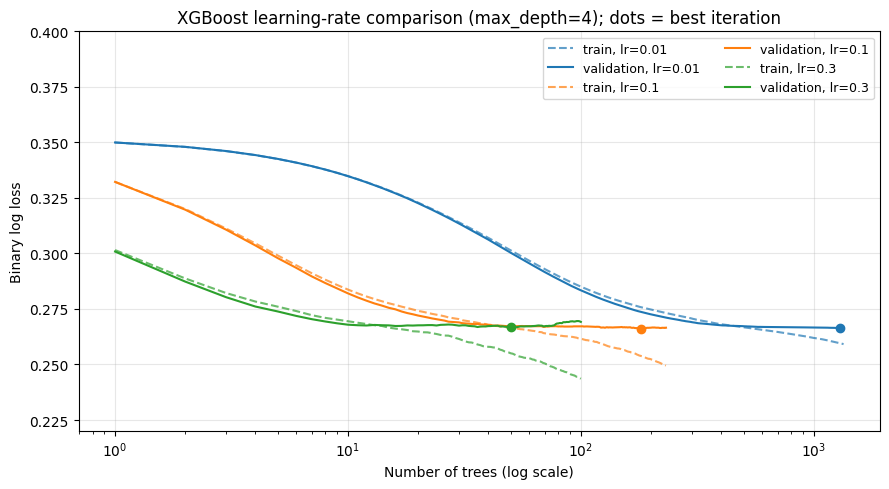

In [21]:
fig, ax = plt.subplots(figsize=(9, 5))
colors = {0.01: "tab:blue", 0.1: "tab:orange", 0.3: "tab:green"}
for record in phase_a:
    model = gbdt_models[record["config"]]
    history = model.evals_result()
    lr = record["learning_rate"]
    rounds = np.arange(1, len(history["validation_1"]["logloss"]) + 1)  # 1-based so round 1 shows on a log axis
    ax.plot(rounds, history["validation_0"]["logloss"], color=colors[lr], linestyle="--", alpha=0.7, label=f"train, lr={lr}")
    ax.plot(rounds, history["validation_1"]["logloss"], color=colors[lr], label=f"validation, lr={lr}")
    ax.scatter(record["best_iteration"] + 1, record["valid_logloss"], color=colors[lr], zorder=5)

ax.set_xscale("log")
ax.set_ylim(0.22, 0.40)
ax.set_xlabel("Number of trees (log scale)")
ax.set_ylabel("Binary log loss")
ax.set_title(f"XGBoost learning-rate comparison (max_depth={GBDT_BASE_PARAMS['max_depth']}); dots = best iteration")
ax.legend(ncol=2, fontsize=9)
ax.grid(alpha=0.3)
fig.tight_layout()
fig.savefig("fig_gbdt_learning_rates.png", dpi=200, bbox_inches="tight")
plt.show()

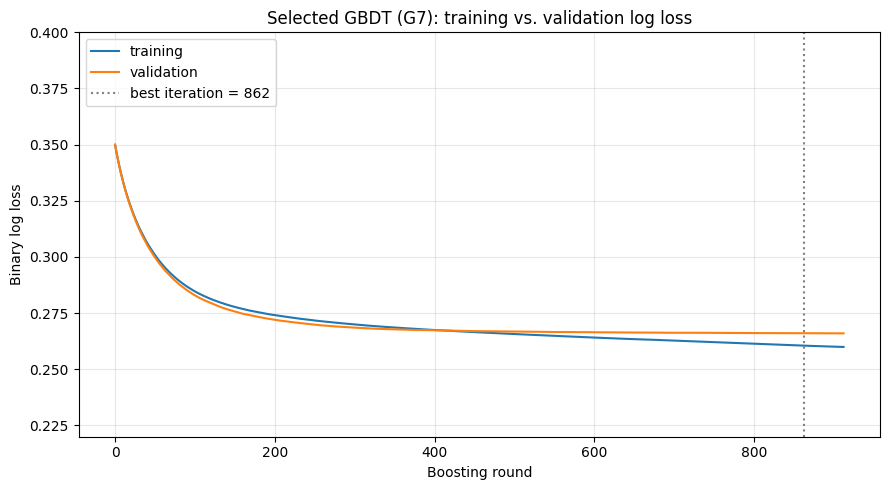

In [22]:
history = gbdt_selected.evals_result()
best_it = gbdt_selected.best_iteration

fig, ax = plt.subplots(figsize=(9, 5))
ax.plot(history["validation_0"]["logloss"], label="training")
ax.plot(history["validation_1"]["logloss"], label="validation")
ax.axvline(best_it, color="gray", linestyle=":", label=f"best iteration = {best_it}")
ax.set_ylim(0.22, 0.40)
ax.set_xlabel("Boosting round")
ax.set_ylabel("Binary log loss")
ax.set_title(f"Selected GBDT ({GBDT_SELECTED_ID}): training vs. validation log loss")
ax.legend()
ax.grid(alpha=0.3)
fig.tight_layout()
fig.savefig("fig_gbdt_selected_logloss.png", dpi=200, bbox_inches="tight")
plt.show()

### 5.6 Feature importance

Importance measure: **gain**, the average improvement in the training objective from splits on a feature, shown as a share of total gain. One-hot encoding splits each categorical variable into separate columns (for example `poutcome_success`).

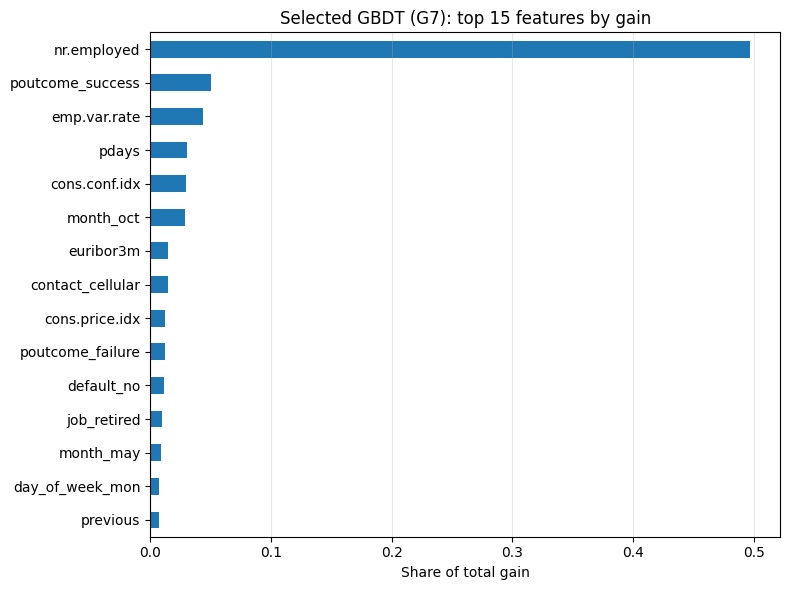

Features used in at least one split: 58 of 63


,gain_share
nr.employed,0.4970
poutcome_success,0.0502
emp.var.rate,0.0435
pdays,0.0305
cons.conf.idx,0.0298
month_oct,0.0291
euribor3m,0.0147
contact_cellular,0.0145
cons.price.idx,0.0119
poutcome_failure,0.0118


In [23]:
gain = pd.Series(gbdt_selected.get_booster().get_score(importance_type="gain"))
gain_share = (gain / gain.sum()).sort_values(ascending=False)
TOP_N = 15

fig, ax = plt.subplots(figsize=(8, 6))
gain_share.head(TOP_N).iloc[::-1].plot.barh(ax=ax, color="tab:blue")
ax.set_xlabel("Share of total gain")
ax.set_title(f"Selected GBDT ({GBDT_SELECTED_ID}): top {TOP_N} features by gain")
ax.grid(axis="x", alpha=0.3)
fig.tight_layout()
fig.savefig("fig_gbdt_feature_importance.png", dpi=200, bbox_inches="tight")
plt.show()

print(f"Features used in at least one split: {len(gain)} of {X_train_tree.shape[1]}")
gain_share.head(TOP_N).round(4).to_frame("gain_share")

**Interpretation.**

- **Learning rate mainly changes how fast boosting converges, not where it ends up.** All three rates reach similar validation AP (about 0.488–0.491). The best validation loss is reached after about 1,300 trees at `0.01`, about 180 at `0.1`, and about 50 at `0.3`. Larger steps reach the minimum sooner and then overfit sooner: at `0.3`, training loss keeps falling well after validation loss has bottomed out, and early stopping ends the run. The AP edge of `0.01` over the other rates is only about 0.001–0.002 — within noise — but under the selection rule it is the rate carried into phases B and C.
- **Depth controls the bias–variance trade-off.** Depth 2 has the highest training and validation loss and needs more than 3,000 trees at this learning rate: it underfits (high bias) and converges slowly. As depth increases, training loss falls faster than validation loss, so the train–validation gap widens from about 0.007 at depth 4 to about 0.03 at depth 8 (higher variance). Validation AP peaks at depth 4–6 and drops at depth 8.
- **Row subsampling has a small regularizing effect.** With `subsample` 0.8 or 0.6, the train–validation gap shrinks slightly and validation AP rises slightly; `subsample = 0.8` gives the highest validation AP of all eight runs.
- **The differences are small.** Validation AP varies by only about 0.01 across all configurations. The validation set has about 700 positives, so gaps this small may partly reflect sampling noise; the selected configuration is a reasonable choice under a fixed rule rather than proof that it is uniquely best.
- **The selected model's curves** show both losses falling quickly over the first ~200 trees. After roughly 400 trees validation loss is almost flat while training loss keeps decreasing, opening a small gap; early stopping keeps the trees up to the best validation iteration.
- **Feature importance is dominated by macroeconomic indicators**, especially `nr.employed` (number employed, about half of total gain), followed by the previous-campaign outcome (`poutcome_success`), other macro indicators, `pdays`, and specific months. The macro indicators are strongly correlated with each other and change with the calendar period of the campaign, so gain can be split among them somewhat arbitrarily, and part of their importance reflects *when* a call happened. This is an association learned by the model, not a causal effect, and it is another reason a random split overstates performance on future campaigns.